Anomaly Detection

Anomaly detection is the identification of rare events, items, or observations which are suspicious because they differ significantly from standard behaviors or patterns. Anomalies in data are also called standard deviations, outliers, noise, novelties, and exceptions.

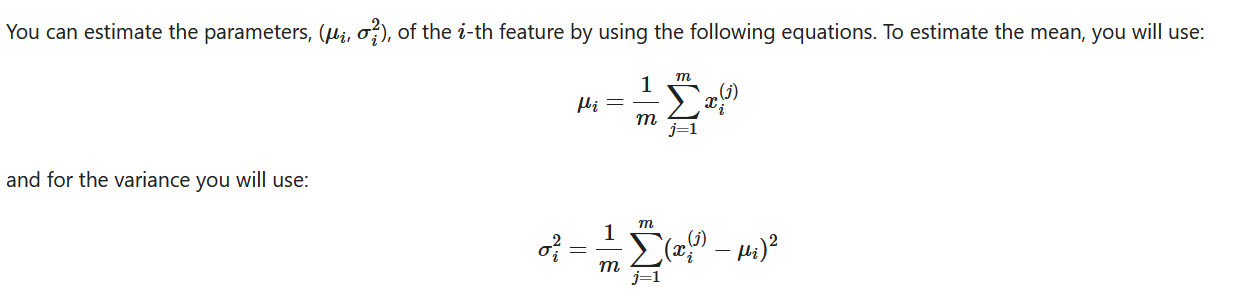
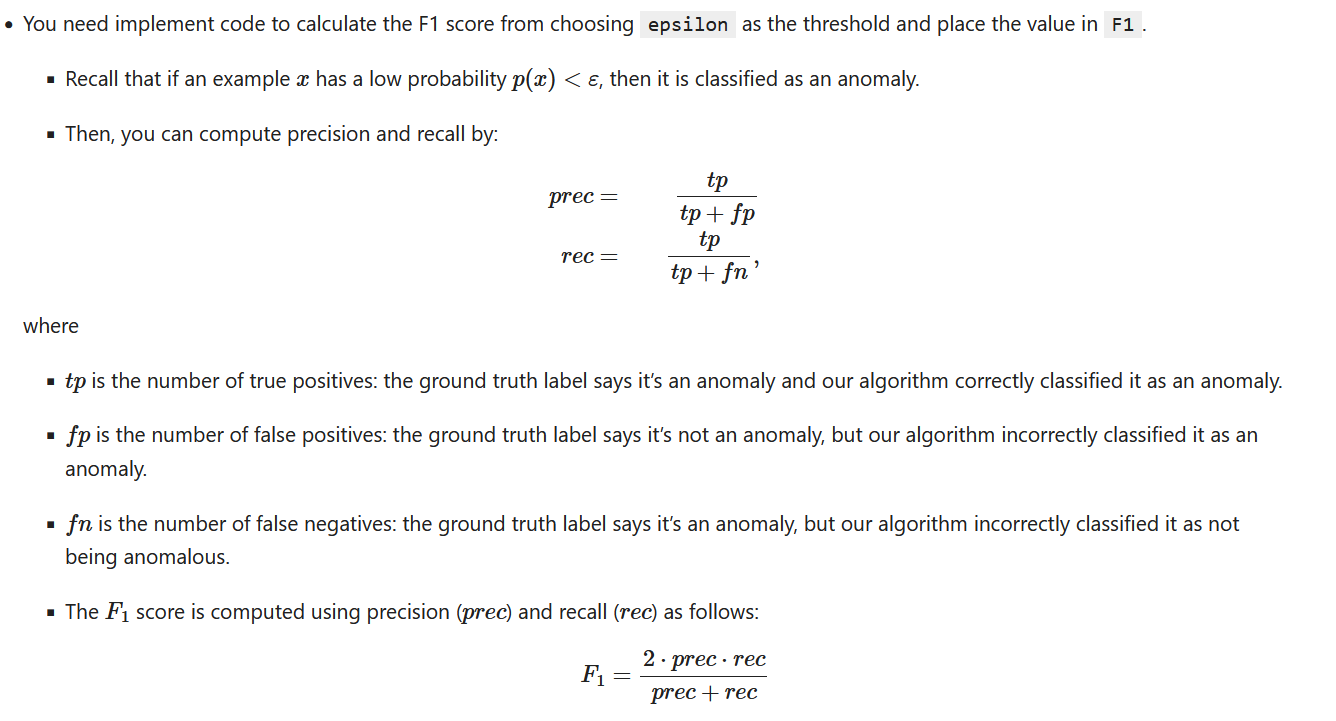

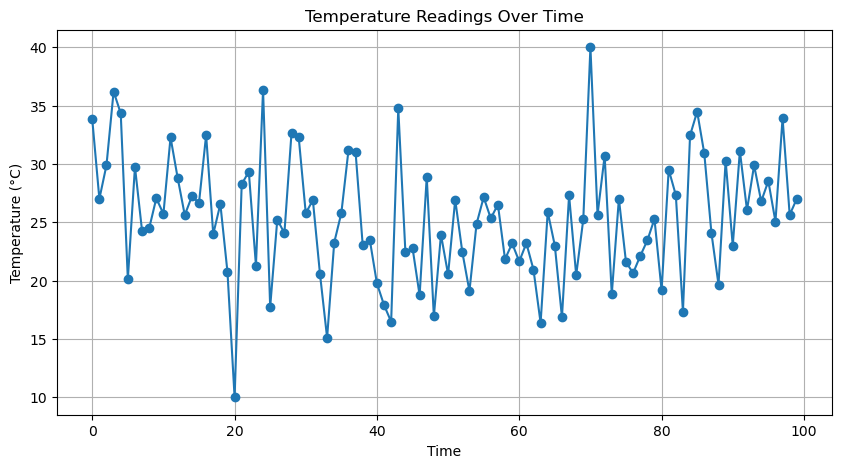

Anomalous Data Points (Indices): [ 3  4 24 43 70 85]


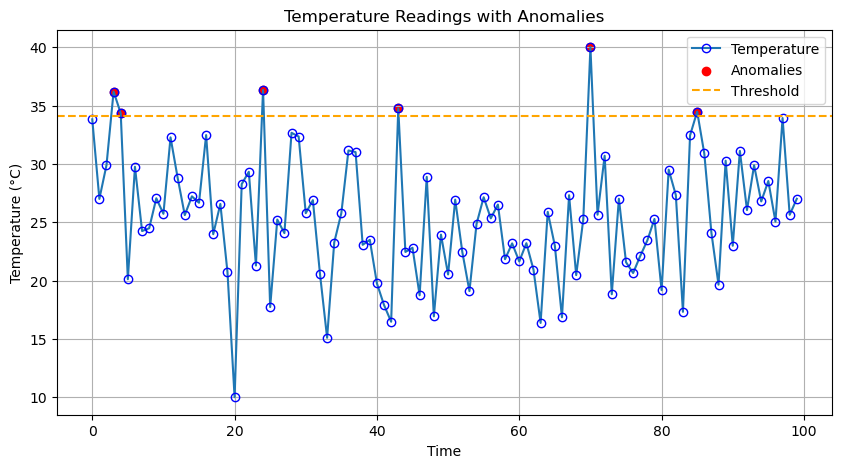

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Generate a synthetic dataset with temperature readings
np.random.seed(0)
# Generate 100 temperature readings around the mean of 25°C with some random noise
temperature_data = np.random.normal(25, 5, 100)
# Introduce anomalies (e.g., extremely high and low temperatures)
temperature_data[20] = 10  # Anomaly: unusually low temperature
temperature_data[70] = 40  # Anomaly: unusually high temperature

# Visualize the temperature data
plt.figure(figsize=(10, 5))
plt.plot(temperature_data, marker='o', linestyle='-')
plt.title("Temperature Readings Over Time")
plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.grid(True)
plt.show()

# Estimate the Gaussian distribution parameters (mean and variance)
mu, std = norm.fit(temperature_data)

# Select the threshold based on the Gaussian distribution
confidence_level = 0.95  # Confidence level for threshold selection
threshold = norm.ppf(confidence_level, mu, std)  # Threshold at the 95% confidence level

# Detect anomalies based on the threshold
anomalies = temperature_data > threshold

# Print the indices of anomalous data points
anomalous_indices = np.where(anomalies)[0]
print("Anomalous Data Points (Indices):", anomalous_indices)

# Visualize the temperature data with anomalies highlighted
plt.figure(figsize=(10, 5))
plt.plot(temperature_data, marker='o', linestyle='-', label='Temperature', markerfacecolor='none', markeredgecolor='blue', markeredgewidth=1)
plt.scatter(anomalous_indices, temperature_data[anomalous_indices], color='red', label='Anomalies')
plt.axhline(threshold, color='orange', linestyle='--', label='Threshold')
plt.title("Temperature Readings with Anomalies")
plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True)
plt.show()


In [12]:
import numpy as np

def estimate_parameters(data):
    """
    Estimate the mean and covariance matrix of the Multivariate Gaussian Distribution.

    Args:
        data (ndarray): Training data with shape (m, n), where m is the number of samples and n is the number of features.

    Returns:
        mu (ndarray): Estimated mean vector with shape (n,).
        sigma (ndarray): Estimated covariance matrix with shape (n, n).
    """
    m, n = data.shape
    mu = np.mean(data, axis=0)
    sigma = (1 / m) * np.dot((data - mu).T, (data - mu))
    return mu, sigma

def multivariate_gaussian(X, mu, sigma):
    """
    Compute the probability density function (PDF) of the Multivariate Gaussian.

    Args:
        X (ndarray): Data points with shape (m, n), where m is the number of samples and n is the number of features.
        mu (ndarray): Mean vector with shape (n,).
        sigma (ndarray): Covariance matrix with shape (n, n).

    Returns:
        p (ndarray): PDF values for each data point with shape (m,).
    """
    n = len(mu)
    det_sigma = np.linalg.det(sigma)
    inv_sigma = np.linalg.inv(sigma)
    X_minus_mu = X - mu
    exponent = np.exp(-0.5 * np.sum(np.dot(X_minus_mu, inv_sigma) * X_minus_mu, axis=1))
    p = (1 / ((2 * np.pi) ** (n / 2) * np.sqrt(det_sigma))) * exponent
    return p

def select_threshold(y_val, p_val):
    """
    Finds the best threshold to use for selecting outliers
    based on the results from a validation set (p_val)
    and the ground truth (y_val) using the F1 score.

    Args:
        y_val (ndarray): Ground truth on validation set (binary labels 0 or 1).
        p_val (ndarray): PDF values on validation set.

    Returns:
        epsilon (float): Threshold chosen.
        F1 (float): F1 score by choosing epsilon as threshold.
    """
    best_epsilon = 0
    best_F1 = 0
    F1 = 0

    step_size = (max(p_val) - min(p_val)) / 1000
    """
        The code sets up a loop to iterate over a range of possible threshold values. 
        It does this by dividing the range between the minimum and maximum values in p_val into 1000 evenly spaced steps 
        Inside the loop, it calculates the F1 score for the current threshold value epsilon using the precision and recall metrics. The precision and recall are calculated based on how well the threshold separates normal data points from outliers.
        If the calculated F1 score (F1) is better (higher) than the previously best F1 score (best_F1), 
        it updates best_F1 and best_epsilon to store the current threshold and its corresponding F1 score as the new best values.
    """

    for epsilon in np.arange(min(p_val), max(p_val), step_size):
        predictions = (p_val < epsilon).astype(int)
        tp = np.sum((predictions == 1) & (y_val == 1))
        fn = np.sum((predictions == 0) & (y_val == 1))
        fp = np.sum((predictions == 1) & (y_val == 0))
        prec = tp / (tp + fp) if tp + fp > 0 else 0
        rec = tp / (tp + fn) if tp + fn > 0 else 0
        F1 = 2 * prec * rec / (prec + rec) if prec + rec > 0 else 0

        if F1 > best_F1:
            best_F1 = F1
            best_epsilon = epsilon

    return best_epsilon, best_F1

import numpy as np

# Generate synthetic data for training and validation
np.random.seed(0)

# Parameters for the Multivariate Gaussian Distribution
mean = [0, 0]  # Mean vector
cov = [[1, 0.5], [0.5, 1]]  # Covariance matrix

# Generate training data
X_train = np.random.multivariate_normal(mean, cov, 300)

# Generate validation data with anomalies
X_val_normal = np.random.multivariate_normal(mean, cov, 200)  # Normal data
X_val_anomalies = np.random.multivariate_normal([3, 3], [[1, 0.5], [0.5, 1]], 50)  # Anomalies
X_val = np.vstack((X_val_normal, X_val_anomalies))

# Generate ground truth labels (0 for normal, 1 for anomalies)
y_val = np.zeros(len(X_val))
y_val[len(X_val_normal):] = 1

# Example usage of the provided code
mu, sigma = estimate_parameters(X_train)
p_val = multivariate_gaussian(X_val, mu, sigma)
epsilon, best_F1 = select_threshold(y_val, p_val)

print(f'Best epsilon: {epsilon}')
print(f'Best F1 score: {best_F1}')

# Anomalileri tespit ediyoruz
anomaly_indices = np.where(p_val < epsilon)
anomalies = X_val[anomaly_indices]



Best epsilon: 0.009128723335474187
Best F1 score: 0.8712871287128714


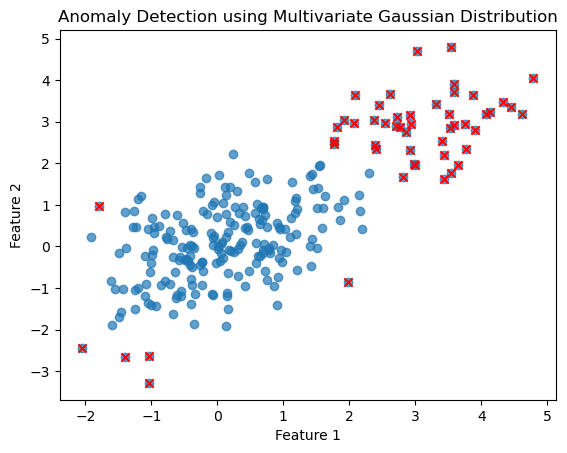

Best epsilon: 0.009128723335474187
Best F1 score: 0.8712871287128714


In [15]:
import matplotlib.pyplot as plt

plt.scatter(X_val[:, 0], X_val[:, 1], alpha=0.7)
plt.scatter(X_val[anomaly_indices, 0], X_val[anomaly_indices, 1], color='red', marker='x')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Anomaly Detection using Multivariate Gaussian Distribution')
plt.show()

# Print the best epsilon and F1 score
print(f'Best epsilon: {epsilon}')
print(f'Best F1 score: {best_F1}')

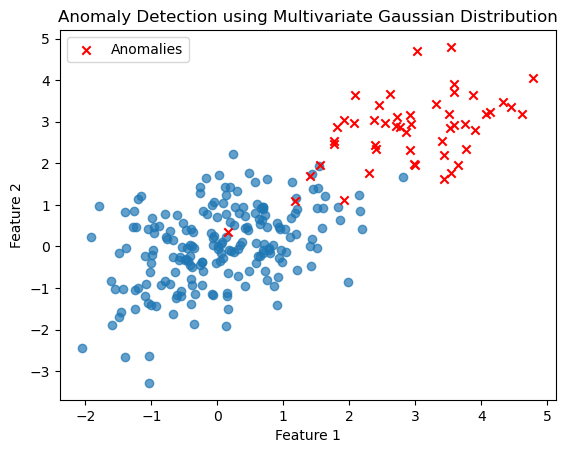

In [17]:
# Plot the data points and highlight anomalies
plt.scatter(X_val_normal[:, 0], X_val_normal[:, 1], alpha=0.7)
plt.scatter(X_val_anomalies[:, 0], X_val_anomalies[:, 1], label='Anomalies', color='red', marker='x')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()
plt.title('Anomaly Detection using Multivariate Gaussian Distribution')
plt.show()
